# Simplex Method from Scratch

Implementation of the primal simplex method for linear programs in standard form, with a graphical view of the path it follows on the feasible region.

The algorithm uses NumPy only; SciPy's `linprog` is used just to double-check the results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# Tolerance for comparisons with zero: floating point arithmetic introduces
# small rounding errors, so "zero" really means "|value| <= TOL".
TOL = 1e-9

## Problem in standard form

The solver works on problems of the form

$$\max\ c^T x \quad \text{s.t.} \quad Ax = b,\ x \ge 0.$$

Each $\le$ constraint becomes an equality by adding one slack variable. Example from the course slides:

$$
\begin{aligned}
\max\ & 4x_1 + x_2 \\
\text{s.t.}\ & x_1 - x_2 \le 3 \\
& 2x_1 + x_2 \le 5 \\
& x_1 \le 2 \\
& x_1, x_2 \ge 0
\end{aligned}
$$

With the slacks $x_3, x_4, x_5$ the constraints become equalities. Since $b \ge 0$, the origin is feasible and the slacks form the initial basis.

In [2]:
# objective coefficients: original variables x1, x2, then the three slacks
c = np.array([4, 1, 0, 0, 0], dtype=float)

# one row per constraint, one column per variable (slacks form an identity block)
A = np.array([[1, -1, 1, 0, 0],
              [2,  1, 0, 1, 0],
              [1,  0, 0, 0, 1]], dtype=float)
b = np.array([3, 5, 2], dtype=float)

# initial basis: the slack columns (0-based indices), i.e. we start at the origin
base = [2, 3, 4]

## Building blocks

Each iteration of the simplex does five things, each in its own function:

1. `base_solution` - where am I? (current basic solution)
2. `reduced_costs` - how steep is each edge leaving this vertex?
3. `entering_variable` - which edge do I follow? (Dantzig's rule)
4. `direction` - how do the basic variables change along that edge?
5. `ratio_test` - how far can I go before hitting a wall? (leaving variable)

In [3]:
def base_solution(A: np.ndarray, b: np.ndarray, base: list) -> np.ndarray:
    """Compute the basic solution associated with a basis.

    Non-basic variables are set to zero, basic variables solve A_B x_B = b.

    Parameters
    ----------
    A : constraint matrix (m x n).
    b : right-hand side (m,).
    base : list of the m column indices in the basis.

    Returns
    -------
    x : full solution vector (n,).
    """
    # keep only the columns of the basis
    A_B = A[:, base]
    # solve A_B x_B = b (no explicit inverse: faster and more accurate)
    x_B = np.linalg.solve(A_B, b)
    # every variable starts at zero, then the basic ones get their values
    x = np.zeros(A.shape[1])
    x[base] = x_B

    return x

In [4]:
def reduced_costs(A: np.ndarray, c: np.ndarray, base: list) -> np.ndarray:
    """Compute the reduced costs r = c - pi^T A.

    The multipliers pi solve A_B^T pi = c_B. The reduced cost r_j is the
    rate of change of the objective if x_j enters the basis; it is zero
    for every basic variable.

    Parameters
    ----------
    A : constraint matrix (m x n).
    c : objective coefficients (n,).
    base : list of the m column indices in the basis.

    Returns
    -------
    r : reduced costs (n,).
    """
    A_B = A[:, base]
    c_B = c[base]
    # simplex multipliers: A_B^T pi = c_B
    pi = np.linalg.solve(A_B.T, c_B)
    r = c - pi @ A

    return r

In [5]:
def entering_variable(r: np.ndarray) -> int | None:
    """Choose the entering variable with Dantzig's rule (largest reduced cost).

    Parameters
    ----------
    r : reduced costs (n,).

    Returns
    -------
    q : index of the entering variable, or None if no reduced cost is
        positive, which means the current solution is optimal.
    """
    # index of the steepest edge
    q = int(np.argmax(r))

    # no edge goes up: the current vertex is optimal
    if r[q] <= TOL:
        return None

    return q

In [6]:
def direction(A: np.ndarray, base: list, q: int) -> np.ndarray:
    """Compute how the basic variables move when x_q increases.

    Along the edge, x_B changes as x_B + t * y_B with y_B = -A_B^{-1} A_q.

    Parameters
    ----------
    A : constraint matrix (m x n).
    base : list of the m column indices in the basis.
    q : index of the entering variable.

    Returns
    -------
    y_B : direction of the basic variables (m,).
    """
    A_B = A[:, base]
    A_q = A[:, q]
    # solve A_B d = A_q instead of computing the inverse, then flip the sign
    y_B = -np.linalg.solve(A_B, A_q)

    return y_B

In [7]:
def ratio_test(x_B: np.ndarray, y_B: np.ndarray) -> tuple[int | None, float]:
    """Minimum ratio test: find the first basic variable that hits zero.

    Only the variables that decrease along the direction (y_B[i] < 0) can
    block the step; each one reaches zero at t = x_B[i] / -y_B[i].

    Parameters
    ----------
    x_B : current values of the basic variables (m,).
    y_B : direction of the basic variables (m,).

    Returns
    -------
    p : position in the basis list of the leaving variable (so the basis
        update is simply base[p] = q), or None if no variable decreases,
        which means the problem is unbounded.
    t : step length (np.inf if unbounded).
    """
    p = None
    t_min = np.inf

    for i in range(len(x_B)):
        # only decreasing variables can become negative
        if y_B[i] < -TOL:
            ratio = x_B[i] / -y_B[i]
            # strict "<": on ties the first index wins
            if ratio < t_min:
                t_min = ratio
                p = i

    return p, t_min

## The simplex loop

The main function glues the five steps together. It receives `c`, `A`, `b`, so it works on any problem in standard form, and the initial basis is a parameter (finding one in general requires the two-phase method, which is not implemented here).

In [8]:
def simplex(c: np.ndarray, A: np.ndarray, b: np.ndarray, base: list,
            max_iter: int = 100) -> dict:
    """Solve max c^T x s.t. Ax = b, x >= 0 with the primal simplex method.

    Parameters
    ----------
    c : objective coefficients (n,).
    A : constraint matrix (m x n).
    b : right-hand side (m,).
    base : list of m column indices forming a feasible initial basis.
    max_iter : maximum number of iterations, a safeguard against cycling
        on degenerate vertices.

    Returns
    -------
    result : dict with keys
        "status" : "optimal", "unbounded" or "max_iter"
        "x"      : final solution (None if unbounded)
        "z"      : objective value (np.inf if unbounded)
        "path"   : list of the visited basic solutions, in order
        "base"   : final basis

    Raises
    ------
    ValueError
        If the initial basis is not feasible.
    """
    # work with floats: with integer arrays numpy silently truncates decimals
    c = np.asarray(c, dtype=float)
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    # copy the basis so the caller's list is not modified
    base = list(base)

    # the starting vertex must be feasible (x >= 0)
    x = base_solution(A, b, base)
    if np.any(x < -TOL):
        raise ValueError("The initial basis is not feasible: "
                         "some basic variables are negative.")

    path = [x.copy()]

    for _ in range(max_iter):
        # 1-2. where am I and how steep is each edge
        r = reduced_costs(A, c, base)

        # 3. no improving edge: optimal
        q = entering_variable(r)
        if q is None:
            return {"status": "optimal", "x": x, "z": c @ x,
                    "path": path, "base": base}

        # 4-5. move along the edge until the first wall
        y_B = direction(A, base, q)
        p, _ = ratio_test(x[base], y_B)

        # nothing blocks the step: the objective grows forever
        if p is None:
            return {"status": "unbounded", "x": None, "z": np.inf,
                    "path": path, "base": base}

        # pivot: x_q takes the place of the leaving variable
        base[p] = q
        x = base_solution(A, b, base)
        path.append(x.copy())

    return {"status": "max_iter", "x": x, "z": c @ x,
            "path": path, "base": base}

## Plot

With two original variables the problem can be drawn in the plane: feasible region, constraint lines, the vertices visited by the simplex and, at the optimum, the level line of the objective. The slack columns are ignored: only the first two columns of `A` are used.

In [9]:
def plot_simplex(A: np.ndarray, b: np.ndarray, c: np.ndarray, result: dict,
                 x1_max: float = 4.0, x2_max: float = 6.0) -> None:
    """Draw feasible region, constraints and simplex path of a 2-variable problem.

    Assumes the first two columns of A are the original variables x1, x2
    and the remaining ones are the slacks of <= constraints.

    Parameters
    ----------
    A, b, c : problem data in standard form.
    result : dict returned by simplex().
    x1_max, x2_max : upper limits of the axes.
    """
    # values of x1 and x2 used to build the grid over the plane
    x1_values = np.linspace(0, x1_max, 400)
    x2_values = np.linspace(0, x2_max, 400)

    # grid: every point of the plane has its coordinates in X1 and X2
    X1, X2 = np.meshgrid(x1_values, x2_values)

    # start from the points with x1 >= 0 and x2 >= 0
    mask = (X1 >= 0) & (X2 >= 0)

    # for each constraint keep only the points on the right side of the wall
    # (only the first two columns of A: slacks are not needed for drawing)
    for i in range(A.shape[0]):
        mask = mask & (A[i, 0] * X1 + A[i, 1] * X2 <= b[i] + TOL)

    fig, ax = plt.subplots(figsize=(7, 7))

    # shade the feasible region, i.e. the points where mask is true
    ax.contourf(X1, X2, mask.astype(float), levels=[0.5, 1.5],
                colors=["tab:blue"], alpha=0.25)

    # draw the line of each constraint (its wall)
    for i in range(A.shape[0]):
        label = f"constraint {i + 1}"
        if abs(A[i, 1]) > TOL:
            # usual case: write x2 as a function of x1
            x2_line = (b[i] - A[i, 0] * x1_values) / A[i, 1]
            ax.plot(x1_values, x2_line, color=f"C{i + 1}", label=label)
        else:
            # x2 does not appear in the constraint: vertical line x1 = b / a
            ax.axvline(b[i] / A[i, 0], color=f"C{i + 1}", label=label)

    # simplex path: keep only x1 and x2 of each visited point
    path = np.array([point[:2] for point in result["path"]])

    # polyline from one vertex to the next
    ax.plot(path[:, 0], path[:, 1], color="black", marker="o",
            linewidth=2.5, label="simplex path")

    # write the step number next to each visited vertex
    for k, (px, py) in enumerate(path):
        ax.annotate(f"step {k}", (px, py), textcoords="offset points", xytext=(8, 8))

    # at the optimum, draw the level line c1*x1 + c2*x2 = z
    if result["status"] == "optimal":
        z = result["z"]
        if abs(c[1]) > TOL:
            ax.plot(x1_values, (z - c[0] * x1_values) / c[1], color="gray",
                    linestyle="--", label=f"level line z = {z:g}")
        else:
            ax.axvline(z / c[0], color="gray", linestyle="--",
                       label=f"level line z = {z:g}")

    # axis limits, labels, title, grid and legend
    ax.set_xlim(0, x1_max)
    ax.set_ylim(0, x2_max)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_title(f"Simplex: status = {result['status']}")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right")

    plt.show()

## Quick run on the example

The result is a dictionary with status, solution, objective value, path and final basis.

In [10]:
result = simplex(c, A, b, base)

for key, value in result.items():
    print(f"{key}: {value}")

status: optimal
x: [2. 1. 2. 0. 0.]
z: 9.0
path: [array([0., 0., 3., 5., 2.]), array([2., 0., 1., 1., 0.]), array([2., 1., 2., 0., 0.])]
base: [2, 1, 0]


## Tests

Each case is solved with `simplex()` and with SciPy's `linprog` (HiGHS). `linprog` minimizes, so it receives $-c$ and its objective is flipped back.

In [11]:
def run_test(name: str, c: np.ndarray, A: np.ndarray, b: np.ndarray, base: list,
             x1_max: float, x2_max: float) -> None:
    """Solve a problem with simplex() and with SciPy, compare them and plot the path."""
    result = simplex(c, A, b, base)
    # linprog minimizes: pass -c and flip the sign of the objective
    scipy_res = linprog(-c, A_eq=A, b_eq=b, bounds=(0, None))

    print(f"{name}: {result['status']}, x = {result['x']}, z = {result['z']}, "
          f"final basis = {result['base']}")
    if scipy_res.status == 0:
        print(f"SciPy: optimal, x = {np.round(scipy_res.x, 6)}, z = {-scipy_res.fun:g}")
    else:
        print(f"SciPy: {scipy_res.message}")

    # same optimal value, or both report an unbounded problem (linprog status 3)
    agree = ((result["status"] == "optimal" and scipy_res.status == 0
              and np.isclose(result["z"], -scipy_res.fun))
             or (result["status"] == "unbounded" and scipy_res.status == 3))
    print(f"Agrees with SciPy: {agree}")

    plot_simplex(A, b, c, result, x1_max, x2_max)

### Regular case

The example from the slides. Expected optimum $(2, 1)$ with $z = 9$.

Regular: optimal, x = [2. 1. 2. 0. 0.], z = 9.0, final basis = [2, 1, 0]
SciPy: optimal, x = [2. 1. 2. 0. 0.], z = 9
Agrees with SciPy: True


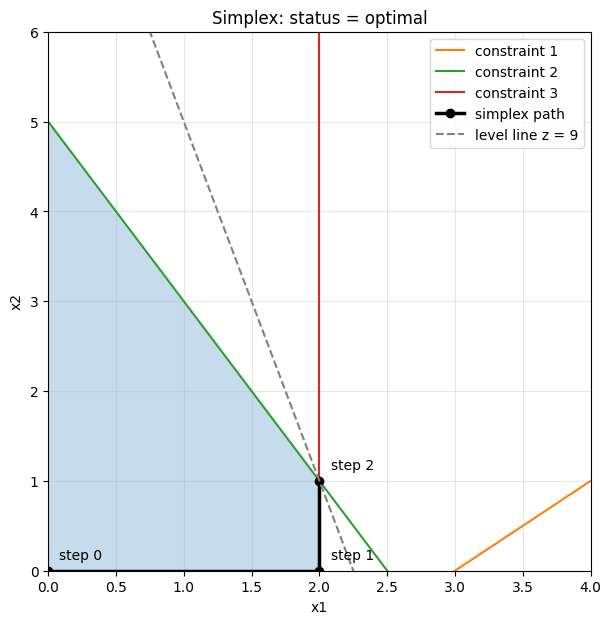

In [12]:
run_test("Regular",
         np.array([4., 1, 0, 0, 0]),
         np.array([[1., -1, 1, 0, 0], [2, 1, 0, 1, 0], [1, 0, 0, 0, 1]]),
         np.array([3., 5, 2]), [2, 3, 4], 4, 6)

### Degenerate case

$\max\ x_1 + 3x_2$ with $4x_1 + 5x_2 \le 10$, $4x_1 + 10x_2 \le 15$, $x_2 \le 1$. Three constraint lines pass through the optimum $(1.25, 1)$, so one basic variable is zero at the end. Expected $z = 4.25$.

Degenerate: optimal, x = [1.25 1.   0.   0.   0.  ], z = 4.25, final basis = [0, 3, 1]
SciPy: optimal, x = [1.25 1.   0.   0.   0.  ], z = 4.25
Agrees with SciPy: True


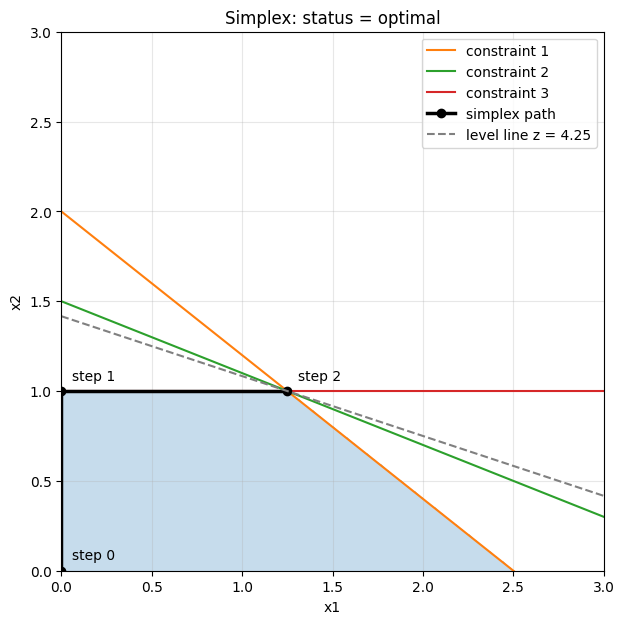

In [13]:
run_test("Degenerate",
         np.array([1., 3, 0, 0, 0]),
         np.array([[4., 5, 1, 0, 0], [4, 10, 0, 1, 0], [0, 1, 0, 0, 1]]),
         np.array([10., 15, 1]), [2, 3, 4], 3, 3)

### Unbounded case

$\max\ x_1 + x_2$ with $x_1 - x_2 \le 1$, $-x_1 + x_2 \le 2$: the feasible region is an infinite strip along the direction $(1, 1)$, so the objective can grow forever. Expected status `unbounded`.

Unbounded: unbounded, x = None, z = inf, final basis = [0, 3]
SciPy: The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible)
Agrees with SciPy: True


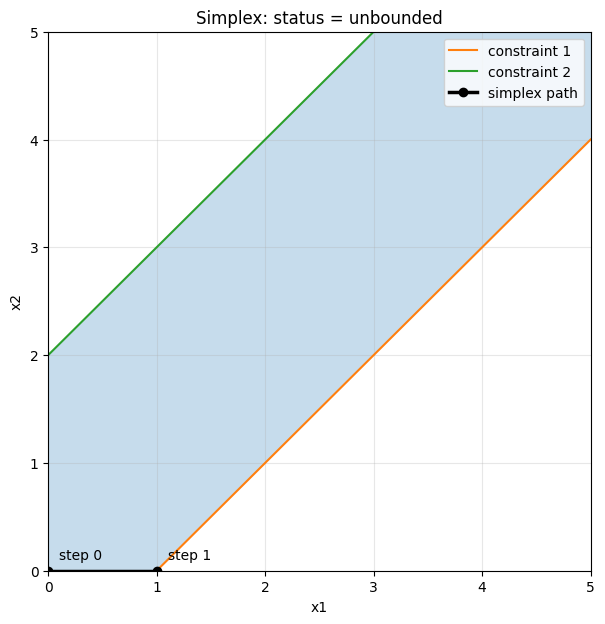

In [14]:
run_test("Unbounded",
         np.array([1., 1, 0, 0]),
         np.array([[1., -1, 1, 0], [-1, 1, 0, 1]]),
         np.array([1., 2]), [2, 3], 5, 5)

## Real case: carpentry workshop

A small carpentry workshop makes tables and chairs.

- A table needs 4 units of wood and 2 hours of work and earns €30.
- A chair needs 2 units of wood and 3 hours of work and earns €20.
- Each week 60 units of wood and 50 hours of work are available.
- The market buys at most 14 chairs per week.

How many tables ($x_1$) and chairs ($x_2$) should be made to maximize the profit?

$$
\begin{aligned}
\max\ & 30x_1 + 20x_2 \\
\text{s.t.}\ & 4x_1 + 2x_2 \le 60 \quad \text{(wood)} \\
& 2x_1 + 3x_2 \le 50 \quad \text{(hours)} \\
& x_2 \le 14 \quad \text{(chairs demand)} \\
& x_1, x_2 \ge 0
\end{aligned}
$$

Expected: 10 tables and 10 chairs, for a profit of €500.

Carpentry: optimal, x = [10. 10.  0.  0.  4.], z = 500.0, final basis = [0, 1, 4]
SciPy: optimal, x = [10. 10.  0.  0.  4.], z = 500
Agrees with SciPy: True


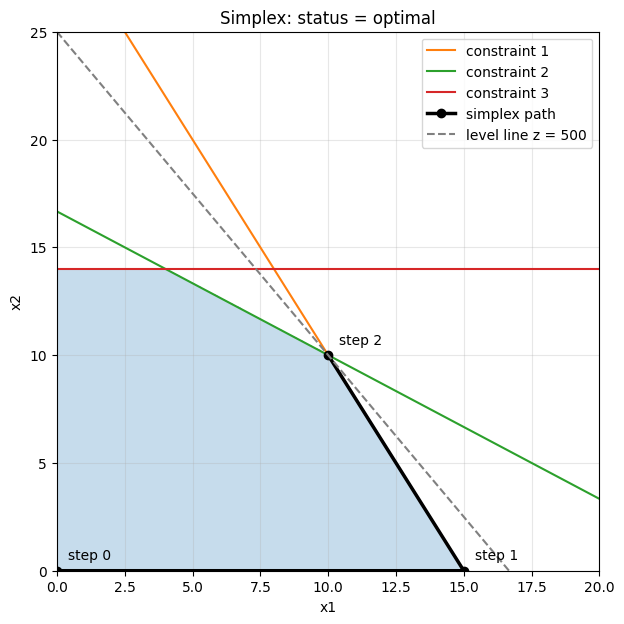

In [15]:
run_test("Carpentry",
         np.array([30., 20, 0, 0, 0]),
         np.array([[4., 2, 1, 0, 0], [2, 3, 0, 1, 0], [0, 1, 0, 0, 1]]),
         np.array([60., 50, 14]), [2, 3, 4], 20, 25)